<a href="https://colab.research.google.com/github/velezverespeter/energy-trading-risk/blob/main/notebooks/01_data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

df = pd.read_csv("ember_si_hourly_prices.csv")
df.head()

,Country,ISO3 Code,Datetime (UTC),Datetime (Local),Price (EUR/MWhe)
0,Slovenia,SVN,2015-01-01 00:00:00,2015-01-01 01:00:00,23.25
1,Slovenia,SVN,2015-01-01 01:00:00,2015-01-01 02:00:00,22.20
2,Slovenia,SVN,2015-01-01 02:00:00,2015-01-01 03:00:00,19.56
3,Slovenia,SVN,2015-01-01 03:00:00,2015-01-01 04:00:00,18.88
4,Slovenia,SVN,2015-01-01 04:00:00,2015-01-01 05:00:00,18.39


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103146 entries, 0 to 103145
Data columns (total 5 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Country           103146 non-null  object 
 1   ISO3 Code         103146 non-null  object 
 2   Datetime (UTC)    103146 non-null  object 
 3   Datetime (Local)  103146 non-null  object 
 4   Price (EUR/MWhe)  101730 non-null  float64
dtypes: float64(1), object(4)
memory usage: 3.9+ MB


In [ ]:
# 1. obdržimo samo stolpca, ki ju potrebujemo, in ju preimenujemo
df = df[["Datetime (UTC)", "Price (EUR/MWhe)"]]
df.columns = ["datetime", "price"]

# 2. besedilo pretvorimo v pravi datum
df["datetime"] = pd.to_datetime(df["datetime"])

# 3. izberemo obdobje 2021–2025
df = df[(df["datetime"] >= "2021-01-01") & (df["datetime"] < "2026-01-01")]

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43824 entries, 52608 to 96431
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   datetime  43824 non-null  datetime64[ns]
 1   price     43824 non-null  float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 1.0 MB


In [ ]:
# podvojene ure
print("Podvojene ure:", df["datetime"].duplicated().sum())

# manjkajoče ure: primerjamo s popolnim seznamom vseh ur
vse_ure = pd.date_range("2021-01-01 00:00", "2025-12-31 23:00", freq="h")
manjkajoce = vse_ure.difference(df["datetime"])
print("Manjkajoče ure:", len(manjkajoce))

# manjkajoče cene
print("Manjkajoče cene:", df["price"].isna().sum())

Podvojene ure: 0
Manjkajoče ure: 0
Manjkajoče cene: 0


In [ ]:
df["price"].describe()

,price
count,43824.000000
mean,137.943440
std,106.948662
min,-500.000000
25%,77.090000
50%,108.000000
75%,166.512500
max,1022.270000


In [ ]:
print("Najnižje cene:")
print(df.nsmallest(5, "price"))
print()
print("Najvišje cene:")
print(df.nlargest(5, "price"))

Najnižje cene:
                 datetime   price
74508 2023-07-02 12:00:00 -500.00
90804 2025-05-11 12:00:00 -126.46
90803 2025-05-11 11:00:00 -126.40
90563 2025-05-01 11:00:00 -124.77
90780 2025-05-10 12:00:00 -119.93

Najvišje cene:
                 datetime    price
84689 2024-08-29 17:00:00  1022.27
84785 2024-09-02 17:00:00   991.29
84784 2024-09-02 16:00:00   958.21
67170 2022-08-30 18:00:00   879.29
67145 2022-08-29 17:00:00   871.00


In [ ]:
negativne = df[df["price"] < 0]
negativne.groupby(negativne["datetime"].dt.year).size()

,0
datetime,
2021,23
2023,96
2024,218
2025,268


In [ ]:
df["local"] = df["datetime"].dt.tz_localize("UTC").dt.tz_convert("Europe/Ljubljana")

df["date"] = df["local"].dt.date
df["hour"] = df["local"].dt.hour
df["weekday"] = df["local"].dt.dayofweek

df.head()

,datetime,price,local,date,hour,weekday
52608,2021-01-01 00:00:00,48.19,2021-01-01 01:00:00+01:00,2021-01-01,1,4
52609,2021-01-01 01:00:00,44.68,2021-01-01 02:00:00+01:00,2021-01-01,2,4
52610,2021-01-01 02:00:00,42.92,2021-01-01 03:00:00+01:00,2021-01-01,3,4
52611,2021-01-01 03:00:00,40.39,2021-01-01 04:00:00+01:00,2021-01-01,4,4
52612,2021-01-01 04:00:00,40.20,2021-01-01 05:00:00+01:00,2021-01-01,5,4


In [ ]:
df["is_peak"] = (df["weekday"] < 5) & (df["hour"] >= 8) & (df["hour"] < 20)

df["is_peak"].value_counts()

,count
is_peak,
False,28176
True,15648


In [ ]:
base = df.groupby("date")["price"].mean()
peak = df[df["is_peak"]].groupby("date")["price"].mean()

daily = pd.DataFrame({"base": base, "peak": peak})
daily.index = pd.to_datetime(daily.index)

daily.head(10)

,base,peak
date,,
2021-01-01,46.405217,49.247500
2021-01-02,33.857917,NaN
2021-01-03,40.925000,NaN
2021-01-04,50.570000,61.125000
2021-01-05,57.294583,66.015833
2021-01-06,47.407083,61.815000
2021-01-07,72.190417,86.690833
2021-01-08,77.922500,99.563333
2021-01-09,52.297917,NaN


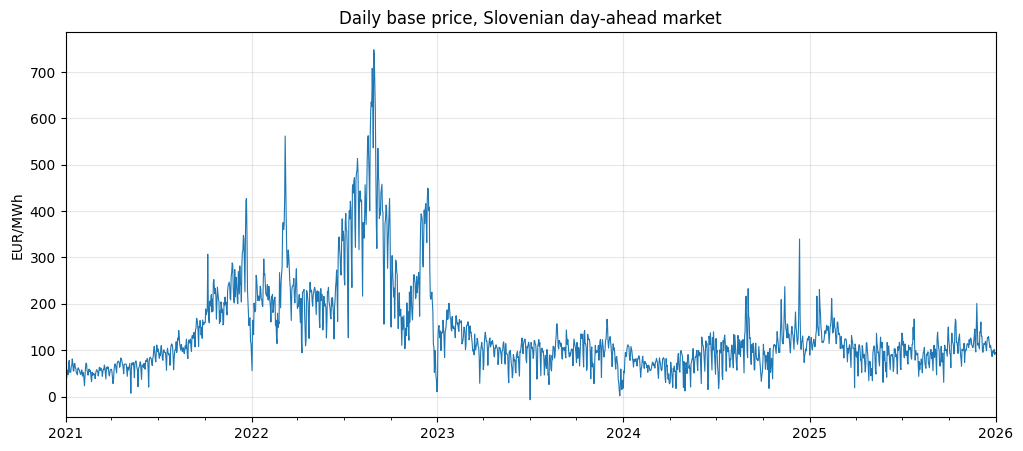

In [ ]:
import matplotlib.pyplot as plt

daily["base"].plot(figsize=(12, 5), linewidth=0.8)
plt.title("Daily base price, Slovenian day-ahead market")
plt.ylabel("EUR/MWh")
plt.xlabel("")
plt.grid(alpha=0.3)
plt.show()

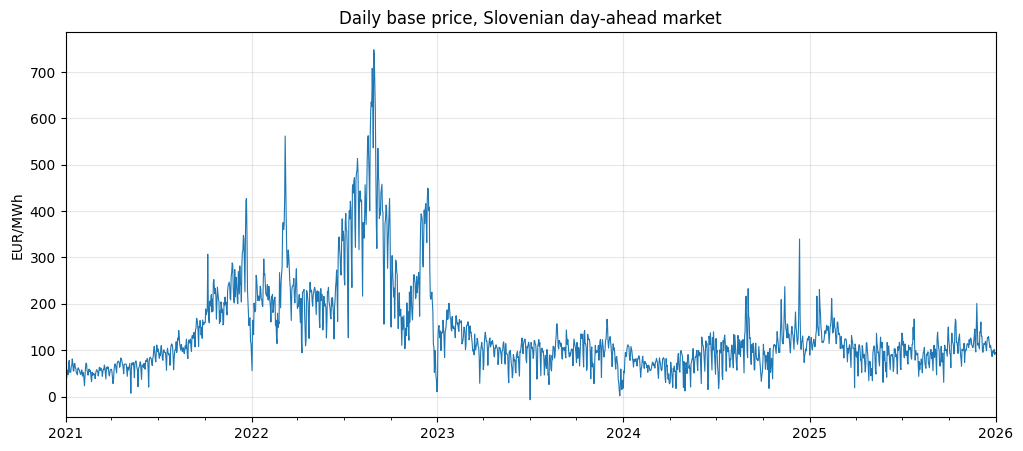

In [ ]:
daily["base"].plot(figsize=(12, 5), linewidth=0.8)
plt.title("Daily base price, Slovenian day-ahead market")
plt.ylabel("EUR/MWh")
plt.xlabel("")
plt.grid(alpha=0.3)
plt.savefig("prices.png", dpi=150, bbox_inches="tight")
plt.show()

daily.to_csv("si_prices_daily.csv")
df.to_csv("si_prices_clean.csv", index=False)